# Credit Card Fraud Detection — Exploratory Data Analysis

## Project Overview

This project explores a credit card transaction dataset to understand transaction patterns and identify characteristics associated with fraudulent transactions.

## Objectives

- Understand the structure and characteristics of the dataset.
- Inspect missing values, duplicate records, and potential outliers.
- Explore numerical and categorical features.
- Analyze relationships between transaction features and the fraud target.
- Summarize the main findings and data preparation decisions.

## Dataset

The dataset contains transaction information, including transaction amounts, timestamps, merchant categories, customer-related attributes, geographic information, and a fraud indicator.

The target variable is `is_fraud`, where `0` represents a legitimate transaction and `1` represents a fraudulent transaction.



# 0. Imports and configuration


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_train = pd.read_csv("archive/fraudTrain.csv")
df_test = pd.read_csv("archive/fraudTest.csv")

print("Training dataset shape:", df_train.shape)
print("Testing dataset shape:", df_test.shape)


Training dataset shape: (1296675, 23)
Testing dataset shape: (555719, 23)


# 01. Data Understanding

This section examines the dataset structure, size, columns, statistical properties, unique values, and class distribution.

In [2]:
df_train.sample(5, random_state=42)

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
1045211,1045211,2020-03-09 15:09:26,577588686219,fraud_Towne LLC,misc_pos,194.51,James,Strickland,M,25454 Leonard Lake,...,40.6153,-79.4545,972,Public relations account executive,1997-10-23,fff87d4340ef756a592eac652493cf6b,1362841766,40.420453,-78.865012,0
547406,547406,2019-08-22 15:49:01,30376238035123,fraud_Friesen Ltd,health_fitness,52.32,Cynthia,Davis,F,7177 Steven Forges,...,42.8250,-124.4409,217,Retail merchandiser,1928-10-01,d0ad335af432f35578eea01d639b3621,1345650541,42.758860,-123.636337,0
110142,110142,2019-03-04 01:34:16,4658490815480264,fraud_Mohr Inc,shopping_pos,6.53,Tara,Richards,F,4879 Cristina Station,...,39.9636,-79.7853,184,Systems developer,1945-11-04,87f26e3ea33f4ff4c7a8bad2c7f48686,1330824856,40.475159,-78.898190,0
1285953,1285953,2020-06-16 20:04:38,3514897282719543,fraud_Gaylord-Powlowski,home,7.33,Steven,Faulkner,M,841 Cheryl Centers Suite 115,...,42.9580,-77.3083,10717,Cytogeneticist,1952-10-13,9c34015321c0fa2ae6fd20f9359d1d3e,1371413078,43.767506,-76.542384,0
271705,271705,2019-05-14 05:54:48,6011381817520024,"fraud_Christiansen, Goyette and Schamberger",gas_transport,64.29,Kristen,Allen,F,8619 Lisa Manors Apt. 871,...,41.6423,-104.1974,635,Product/process development scientist,1973-07-13,198437c05676f485e9be04449c664475,1336974888,41.040392,-104.092324,0


In [3]:
print("Training rows:", f"{df_train.shape[0]:,}")
print("Training columns:", df_train.shape[1])
print("Testing rows:", f"{df_test.shape[0]:,}")
print("Testing columns:", df_test.shape[1])
print("Total rows across both files:", f"{len(df_train) + len(df_test):,}")


Training rows: 1,296,675
Training columns: 23
Testing rows: 555,719
Testing columns: 23
Total rows across both files: 1,852,394


In [4]:
df_train.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [5]:
print("Column names:")
for column in df_train.columns:
    print(column)


Column names:
Unnamed: 0
trans_date_trans_time
cc_num
merchant
category
amt
first
last
gender
street
city
state
zip
lat
long
city_pop
job
dob
trans_num
unix_time
merch_lat
merch_long
is_fraud


In [6]:
df_train.nunique().sort_values(ascending=False)

Unnamed: 0               1296675
trans_num                1296675
merch_long               1275745
unix_time                1274823
trans_date_trans_time    1274791
merch_lat                1247805
amt                        52928
street                       983
cc_num                       983
zip                          970
long                         969
dob                          968
lat                          968
city                         894
city_pop                     879
merchant                     693
job                          494
last                         481
first                        352
state                         51
category                      14
gender                         2
is_fraud                       2
dtype: int64

In [8]:
df_train.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

# 02. Data Cleaning

In [9]:
# Check for duplicate rows
duplicates_count = df_train.duplicated().sum()

print("Number of duplicate rows:", duplicates_count)

Number of duplicate rows: 0


In [10]:
# Statistical summary of transaction amounts
df_train["amt"].describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

In [12]:
Q1 = df_train["amt"].quantile(0.25)
Q3 = df_train["amt"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_train[
    (df_train["amt"] < lower_bound) |
    (df_train["amt"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))
print(
    "Percentage of outliers:",
    round(len(outliers) / len(df_train) * 100, 2),
    "%"
)

Q1: 9.65
Q3: 83.14
IQR: 73.49
Lower Bound: -100.58499999999998
Upper Bound: 193.375
Number of outliers: 67290
Percentage of outliers: 5.19 %


### Outlier Detection Using IQR

The IQR method was applied to the `amt` column to identify unusually large or small transaction amounts. The lower bound was approximately -100.585, and the upper bound was 193.375.

A total of 67,290 transactions (5.19% of the training dataset) were identified as outliers. No values were below the lower bound because all transaction amounts were positive.

These observations will be retained because unusually large transactions may contain useful information for fraud detection. Outliers are not necessarily fraudulent transactions, so removing them without further investigation could lead to information loss.



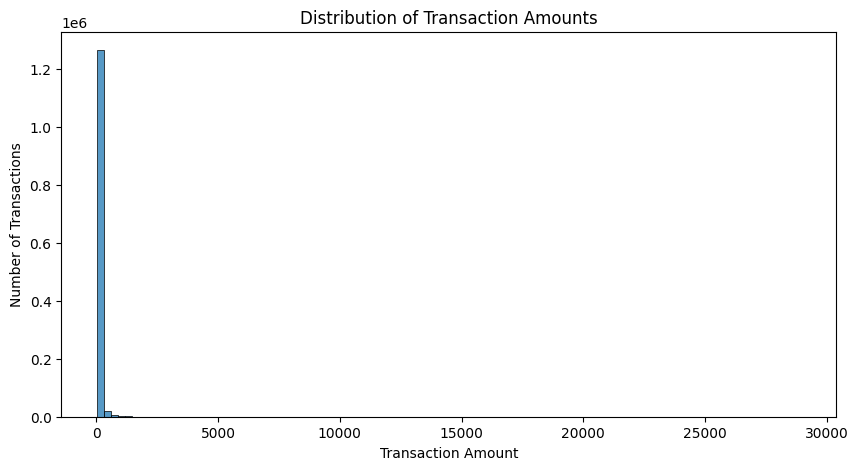

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_train,
    x="amt",
    bins=100
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

### Transaction Amount Distribution

The histogram shows a strongly right-skewed distribution of transaction amounts. Most transactions have relatively small amounts, while a smaller number have much larger amounts. These extreme values stretch the horizontal axis and make the distribution of typical transaction amounts difficult to observe.

The identified outliers will be retained because large transaction amounts may be relevant to fraud detection.



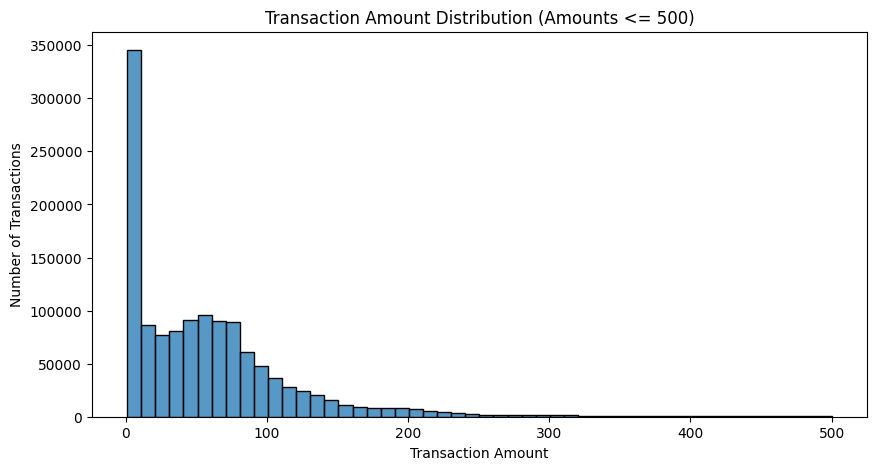

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_train[df_train["amt"] <= 500],
    x="amt",
    bins=50
)

plt.title("Transaction Amount Distribution (Amounts <= 500)")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

### Detailed Transaction Amount Distribution

To better visualize the transaction amounts, a second histogram was created using transactions with amounts less than or equal to 500. This visualization shows that transaction amounts are concentrated at lower values and generally become less frequent as the amount increases.

The distribution remains right-skewed. The filtered data was used for visualization only; no transactions were removed from the original dataset.




In [15]:
# Count legitimate and fraudulent transactions
print(df_train["is_fraud"].value_counts())

# Calculate percentages
print("\nClass percentages:")
print(
    (df_train["is_fraud"].value_counts(normalize=True) * 100).round(2)
)

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Class percentages:
is_fraud
0    99.42
1     0.58
Name: proportion, dtype: float64


In [16]:
# Convert transaction date to datetime
df_train["trans_date_trans_time"] = pd.to_datetime(
    df_train["trans_date_trans_time"]
)

df_test["trans_date_trans_time"] = pd.to_datetime(
    df_test["trans_date_trans_time"]
)

print(df_train["trans_date_trans_time"].dtype)
print(df_test["trans_date_trans_time"].dtype)

datetime64[ns]
datetime64[ns]


# 03. Exploratory Data Analysis (EDA)

This section explores individual features and investigates relationships between transaction characteristics and fraud status.

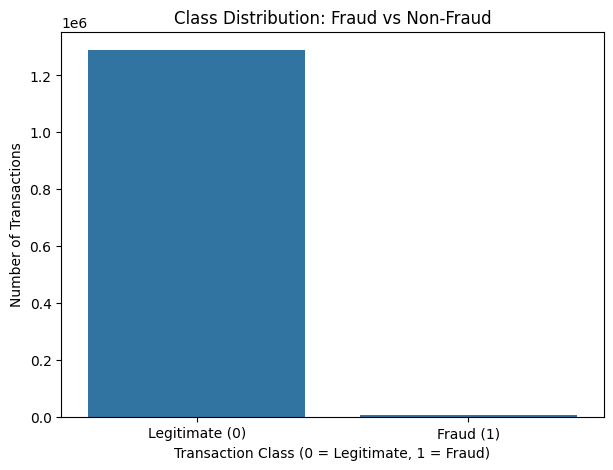

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_train, x="is_fraud")

plt.title("Class Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.show()

Observation: Fraudulent transactions represent a small proportion of the training dataset. This class imbalance means accuracy alone would not be sufficient to evaluate a future fraud detection model; precision, recall, and F1-score should also be considered.

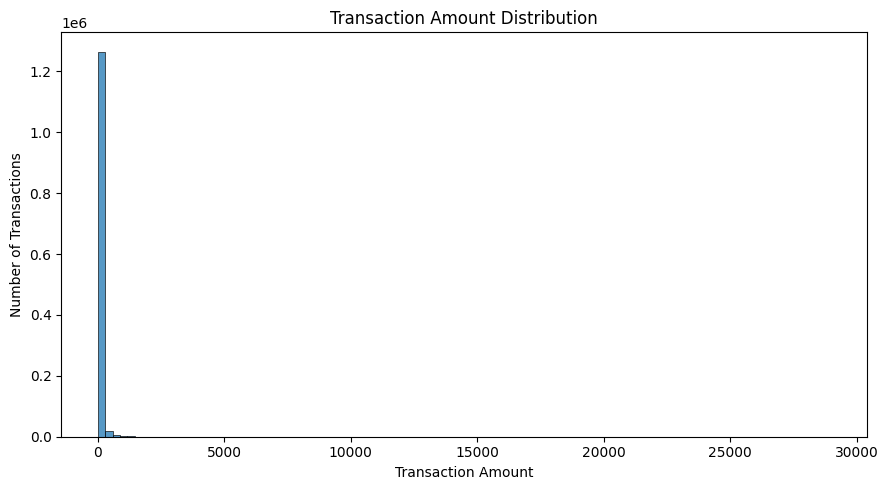

In [19]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_train, x="amt", bins=100)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


In [20]:
amount_by_fraud = df_train.groupby("is_fraud")["amt"].agg(
    count="count", mean="mean", median="median", min="min", max="max"
)
amount_by_fraud


,count,mean,median,min,max
is_fraud,,,,,
0,1289169,67.667110,47.280,1.00,28948.90
1,7506,531.320092,396.505,1.06,1376.04


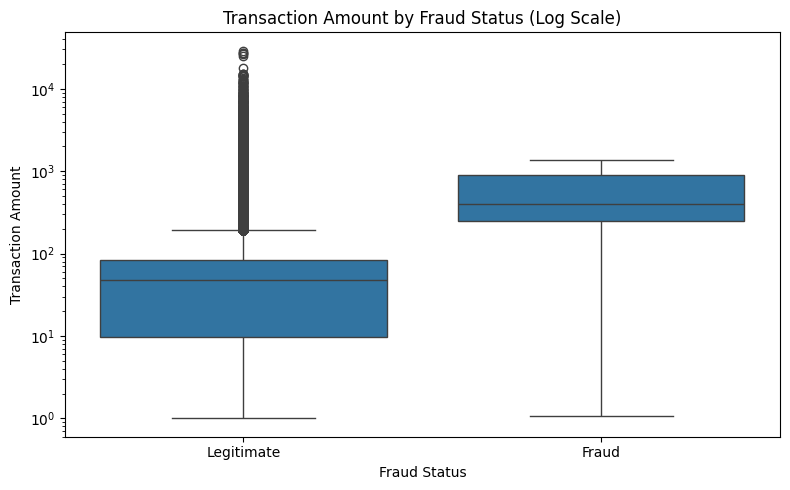

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_train, x="is_fraud", y="amt")
plt.yscale("log")
plt.title("Transaction Amount by Fraud Status (Log Scale)")
plt.xlabel("Fraud Status")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()


Observation: Compare the mean and median amounts in the table above. A difference may indicate that transaction amount is associated with fraud status, but amount alone cannot determine whether a transaction is fraudulent.

In [22]:
fraud_by_category = df_train.groupby("category")["is_fraud"].agg(
    total_transactions="count",
    fraud_transactions="sum",
    fraud_rate="mean"
)
fraud_by_category["fraud_rate"] *= 100
fraud_by_category.sort_values("fraud_rate", ascending=False).round(2)


,total_transactions,fraud_transactions,fraud_rate
category,,,
shopping_net,97543,1713,1.76
misc_net,63287,915,1.45
grocery_pos,123638,1743,1.41
shopping_pos,116672,843,0.72
gas_transport,131659,618,0.47
misc_pos,79655,250,0.31
grocery_net,45452,134,0.29
travel,40507,116,0.29
entertainment,94014,233,0.25


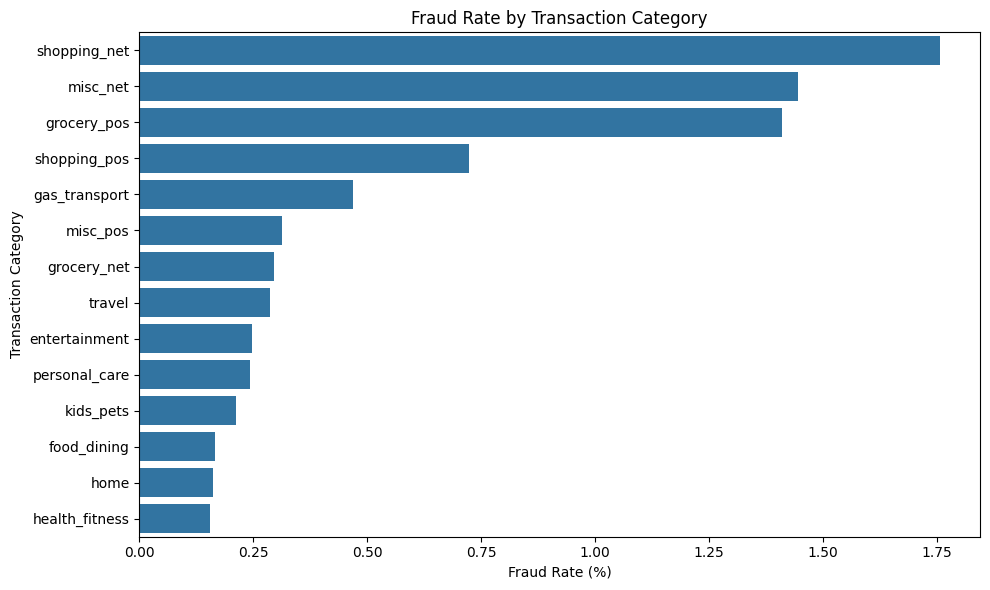

In [23]:
category_plot = fraud_by_category.sort_values("fraud_rate", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=category_plot["fraud_rate"], y=category_plot.index)
plt.title("Fraud Rate by Transaction Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Category")
plt.tight_layout()
plt.show()


Observation: Fraud rates can vary across transaction categories. The categories with the highest observed rates may be worth investigating, but the pattern does not prove that category causes fraud.

In [24]:
gender_fraud = pd.crosstab(
    df_train["gender"],
    df_train["is_fraud"],
    normalize="index"
).mul(100).round(2)

gender_fraud


is_fraud,0,1
gender,,
F,99.47,0.53
M,99.36,0.64


Observation: Compare the fraud percentages across gender groups. Any difference should be interpreted cautiously; this table alone does not establish a meaningful or causal relationship.

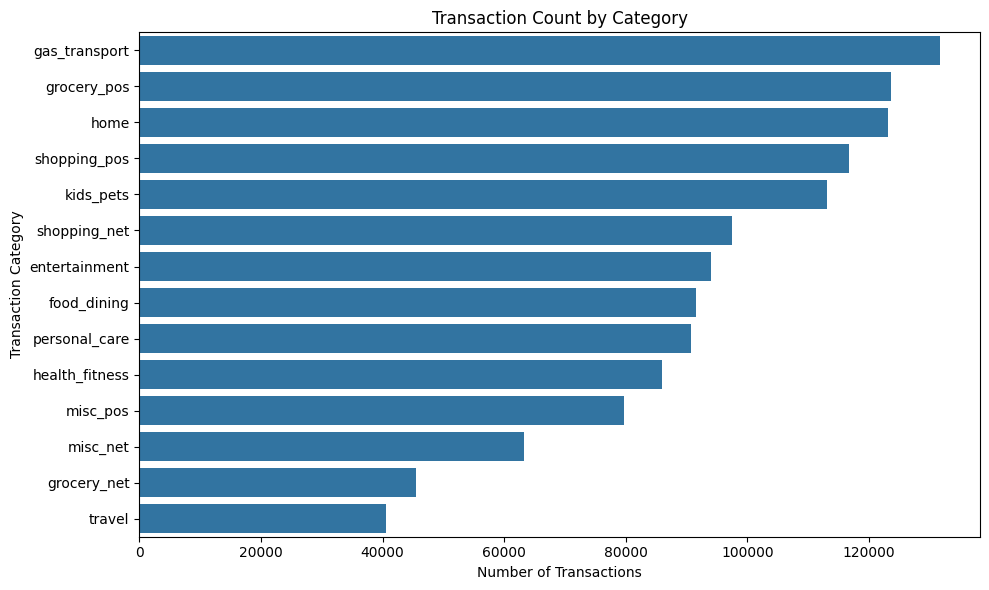

In [25]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_train,
    y="category",
    order=df_train["category"].value_counts().index
)
plt.title("Transaction Count by Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Category")
plt.tight_layout()
plt.show()


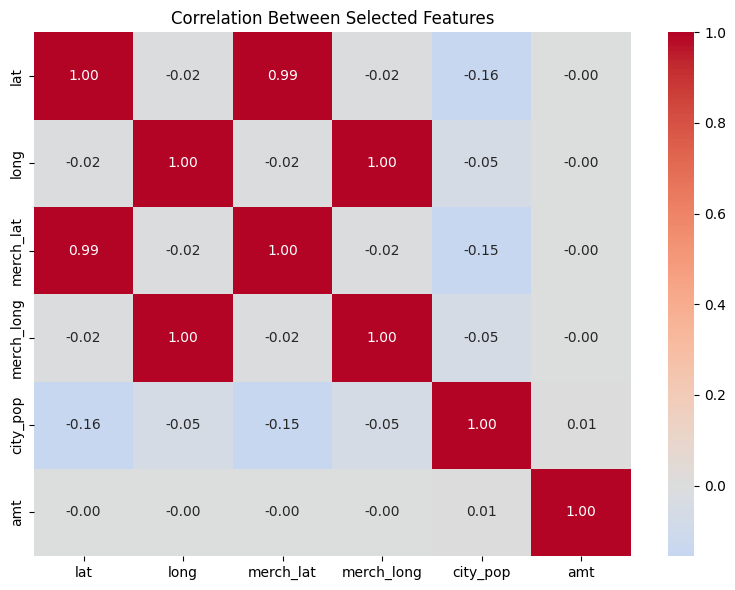

In [26]:
selected_features = ["lat", "long", "merch_lat", "merch_long", "city_pop", "amt"]
feature_corr = df_train[selected_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Selected Features")
plt.tight_layout()
plt.show()


Observation: Customer and merchant coordinates describe locations related to the same transaction. Latitude and longitude pairs may have relationships, but correlation does not measure geographic distance directly. Consider these features together during future feature engineering.

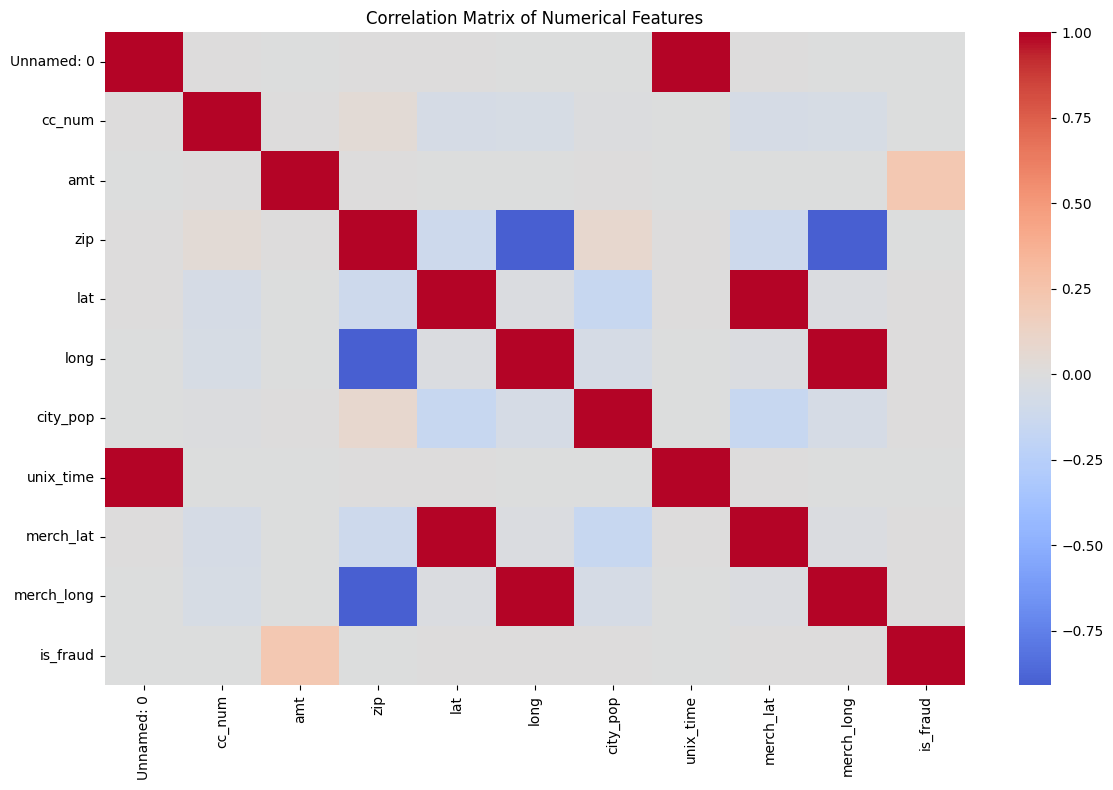

In [27]:
numeric_df = df_train.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


Observation: Correlation measures linear association and does not imply causation. Unnamed: 0, card numbers, transaction identifiers, and timestamp-related fields should be reviewed before modeling because they may act as identifiers or reflect record ordering rather than useful generalizable patterns.


In [29]:
df_train.groupby("is_fraud")["amt"].agg(
    count="count",
    mean="mean",
    median="median",
    min="min",
    max="max"
)


,count,mean,median,min,max
is_fraud,,,,,
0,1289169,67.667110,47.280,1.00,28948.90
1,7506,531.320092,396.505,1.06,1376.04


In [28]:
fraud_by_category.sort_values("fraud_transactions", ascending=False).round(2)


,total_transactions,fraud_transactions,fraud_rate
category,,,
grocery_pos,123638,1743,1.41
shopping_net,97543,1713,1.76
misc_net,63287,915,1.45
shopping_pos,116672,843,0.72
gas_transport,131659,618,0.47
misc_pos,79655,250,0.31
kids_pets,113035,239,0.21
entertainment,94014,233,0.25
personal_care,90758,220,0.24


# 04. Final Findings

Key Findings
- The training dataset contains 1,296,675 rows and 23 columns (verify using the output in this notebook).
- Missing values and fully duplicated rows were checked; use the printed outputs to confirm the results.
- IQR-identified outliers in amt were retained because high transaction amounts may be useful for fraud analysis.
- The target is highly imbalanced, with legitimate transactions forming the majority of records.
- Transaction amounts and fraud rates can differ across fraud status and transaction categories.
- Geographic variables may be related and should be interpreted together.
- Correlation does not imply causation, and identifier-like columns should be reviewed before model training.
Data Cleaning Decisions
- No missing-value imputation is needed if the missing-value check returns zero for all columns.
- Remove duplicate rows only if genuine duplicate records are identified and removal is justified.
- Retain IQR-identified outliers for this EDA.
- Convert the transaction timestamp to datetime.
- No encoding, scaling, feature selection, or model training is performed because this task focuses on EDA.


# Conclusion
The exploratory analysis examines the dataset structure, data quality, transaction amount distribution, fraud-class imbalance, relationships between selected features and the target, and grouped statistics. These findings can guide later feature preparation and model evaluation. Since fraud is rare, accuracy alone will not be sufficient to assess a future fraud detection model.